In [1]:
import matplotlib.pyplot as plt
import numpy as np
from simulate_bounds import MODE_DEGREE  # noqa: F401

from visualize_helpers import (
    draw_fi_curves,
    fi_legend_handles_labeled,
    latexify,
    plot_fi_comparison_labeled,
)

latexify()
FORMAT = "pdf"
continuous_cmaps = [
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "Blues",
    "viridis",
    "plasma",
    "cividis",
    "magma",
    "inferno",
    "turbo",
    "pink",
    "bone",
    "gray",
    "copper",
]

In [2]:
%matplotlib inline

# Load data

In [3]:
coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]
x_range = coords[:, 0, 2]

baseline_ms = np.load("baseline_fi_ms.npy")
baseline_ms_inv = np.load("baseline_fi_ms_inv.npy")

important_modes_ms = np.load("fi_ms_important_modes.npy")
important_modes_ms_inv = np.load("fi_ms_inv_important_modes.npy")

fis = [baseline_ms, important_modes_ms]
fis_inv = [baseline_ms_inv, important_modes_ms_inv]

# One label per field (drawn verbatim in the legend, in this order). Swap these
# for whatever custom FI arrays you load above.
labels = ["baseline", "important modes"]

# s param

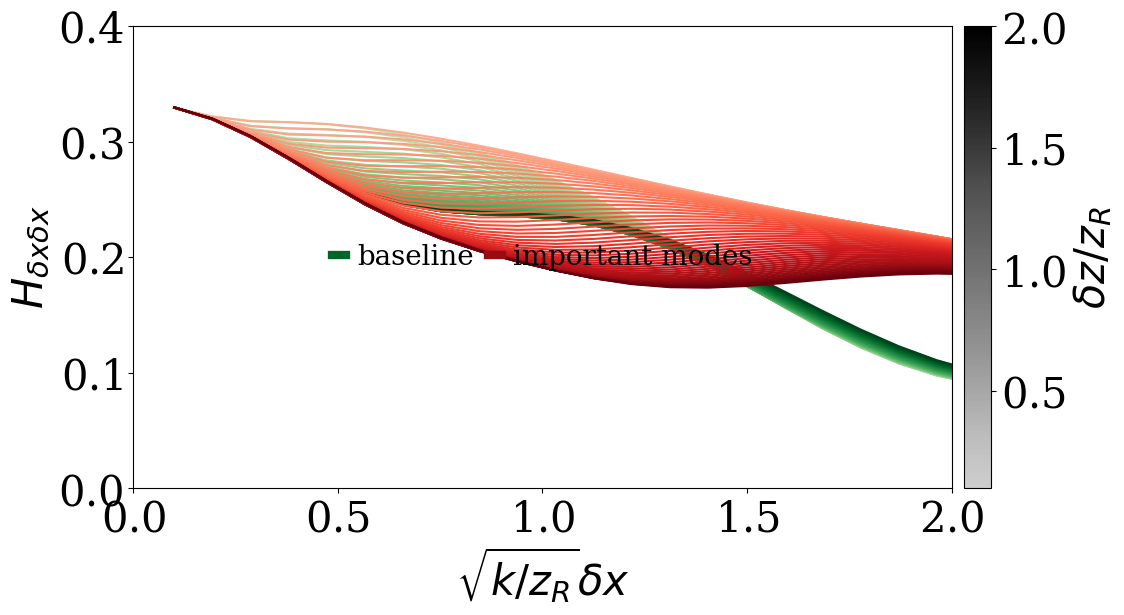

In [4]:
fig, axs = plot_fi_comparison_labeled(
    [np.sum(fi, axis=2)[:, :, 0, 0] for fi in fis],
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 0.4),
    xlim=(0, 2),
)

fig.savefig(
    f"s_param_fi_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

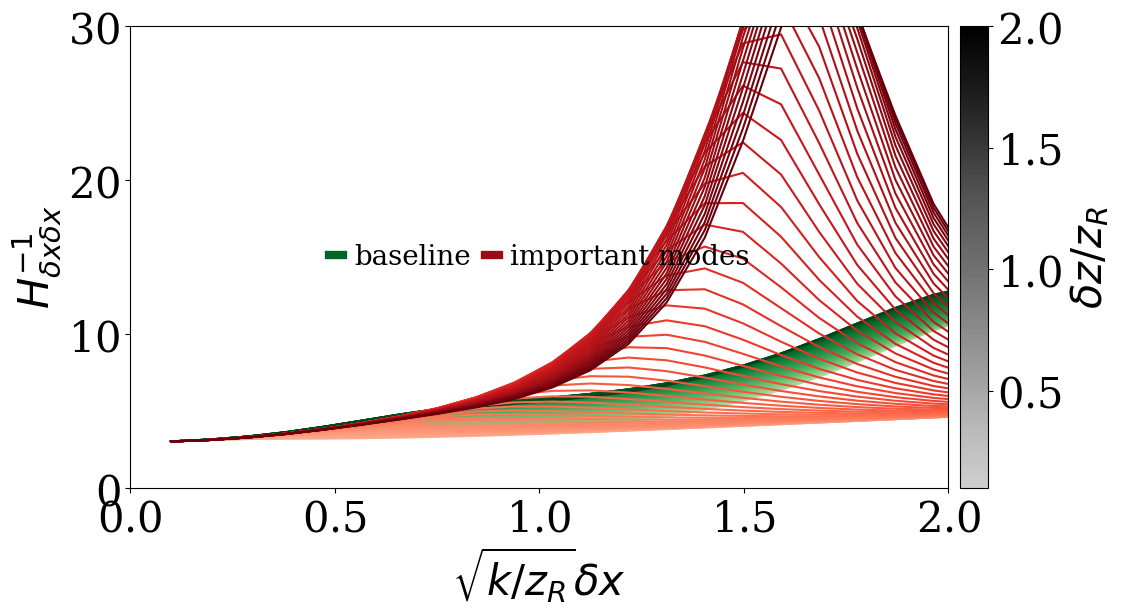

In [5]:
fig, axs = plot_fi_comparison_labeled(
    [fi_inv[:, :, 0, 0] for fi_inv in fis_inv],
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    ylim=(0, 30),
    xlim=(0, 2),
)

fig.savefig(
    f"s_param_crb_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

# p param

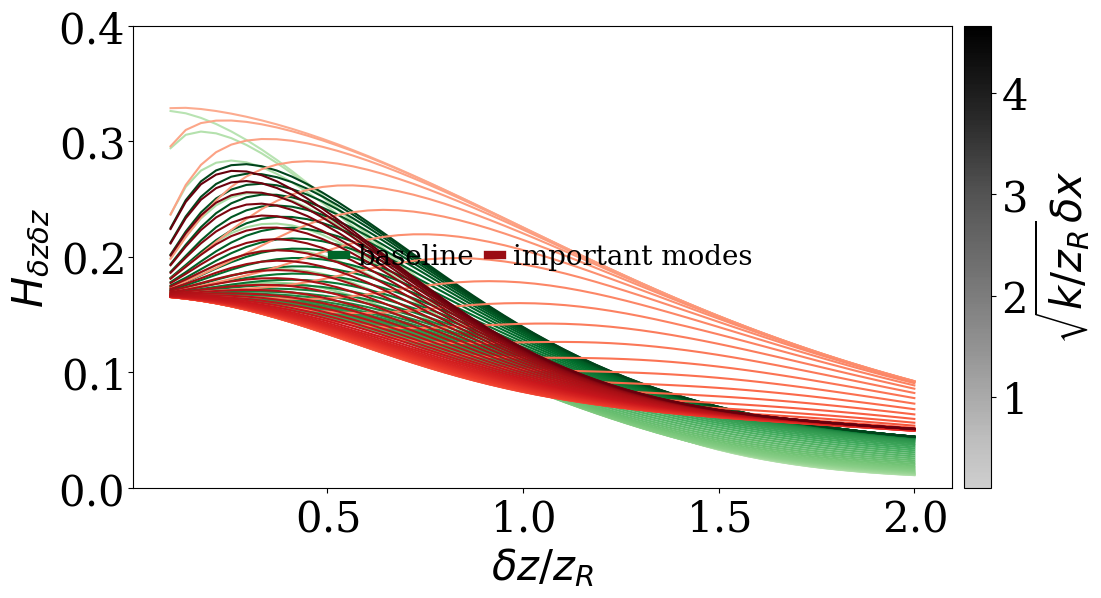

In [6]:
fig, axs = plot_fi_comparison_labeled(
    [np.transpose(np.sum(fi, axis=2)[:, :, 1, 1]) for fi in fis],
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 0.4),
)

fig.savefig(
    f"p_param_fi_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

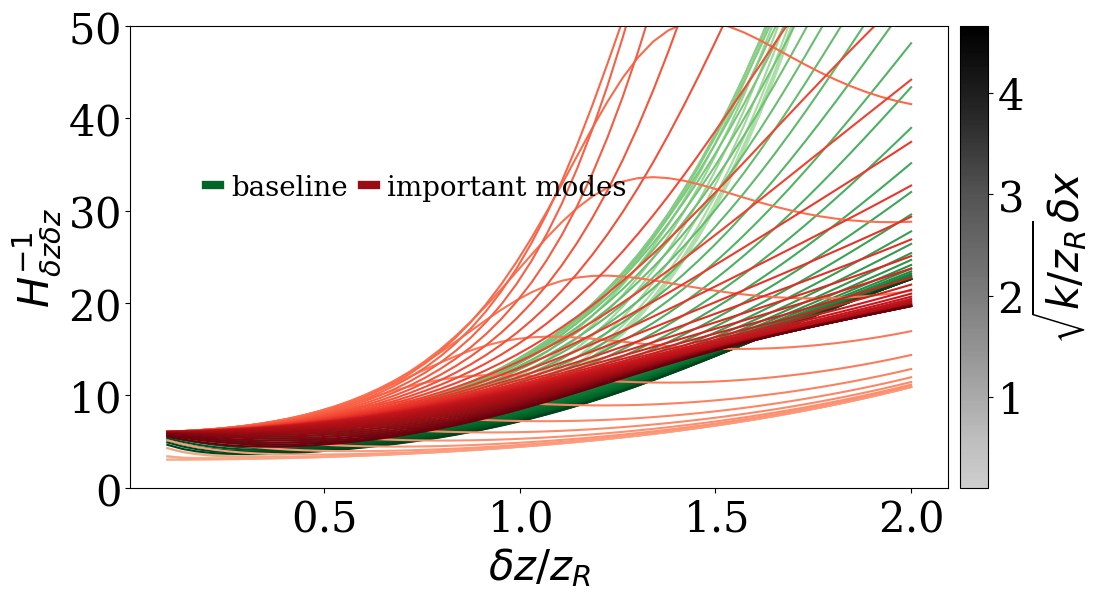

In [7]:
fig, axs = plot_fi_comparison_labeled(
    [np.transpose(fi_inv[:, :, 1, 1]) for fi_inv in fis_inv],
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R} \delta x$",
    ylim=(0, 50),
)

leg = axs[0].get_legend()
handles = leg.legend_handles  # type: ignore
labels_txt = [t.get_text() for t in leg.get_texts()]  # type: ignore
title = leg.get_title().get_text()  # type: ignore

axs[0].legend(
    handles=handles,
    labels=labels_txt,
    title=title,
    frameon=False,
    ncol=2,
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.5,
    loc="center",
    bbox_to_anchor=(0.35, 0.65),
)

fig.savefig(
    f"p_param_crb_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()

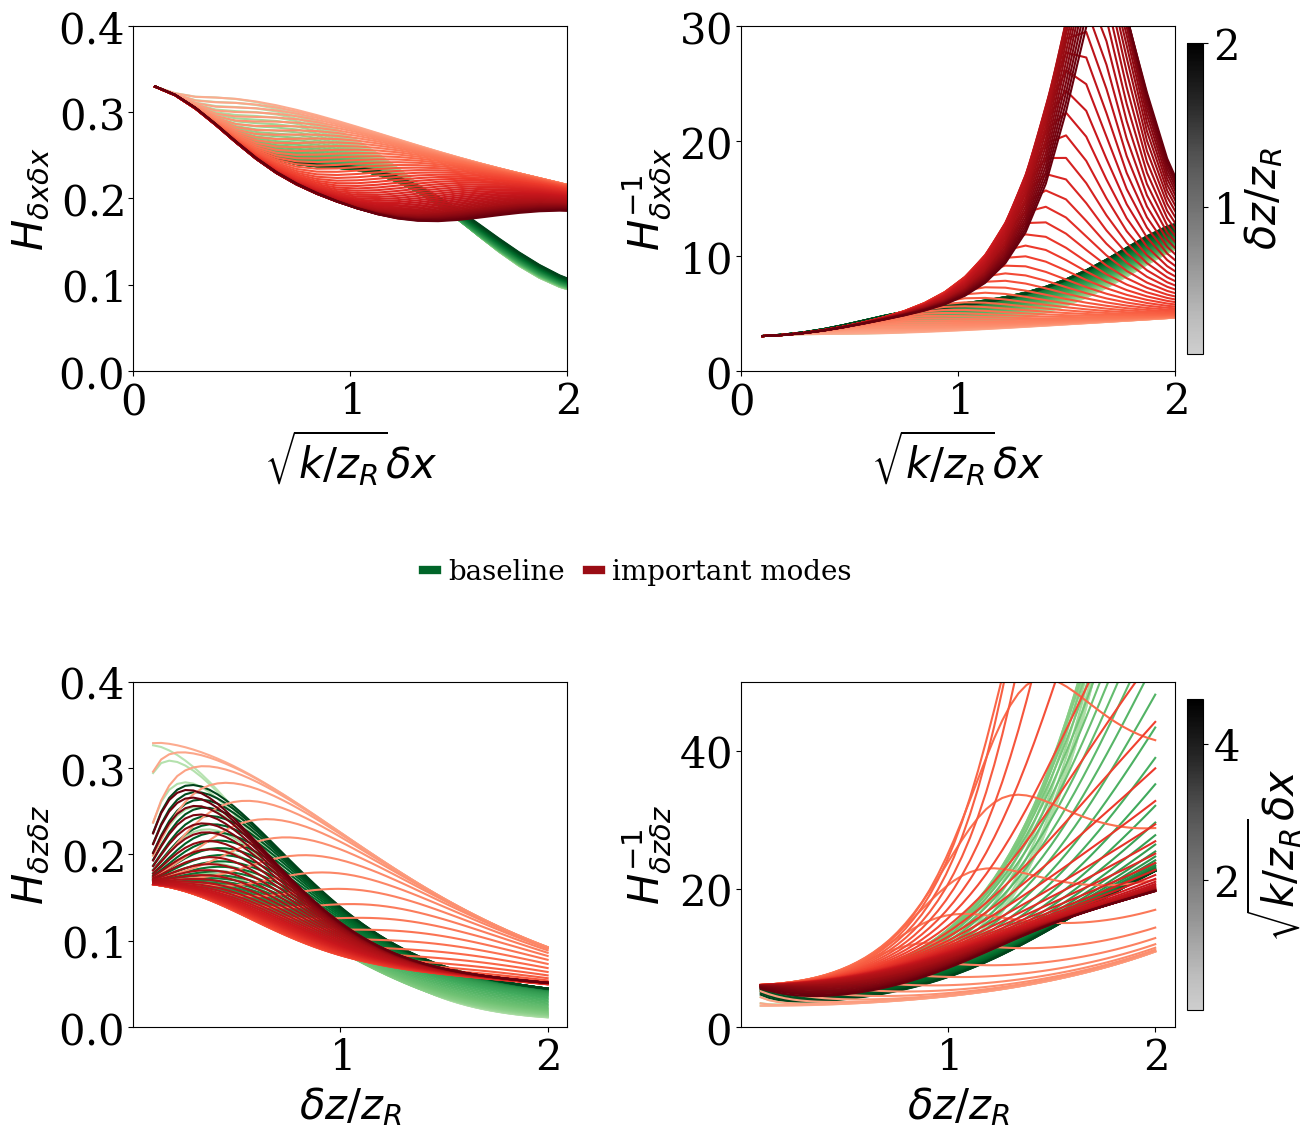

In [8]:
# Combined 2x2 grid: FI (left column) and Cramer-Rao bound (CRB = inverse FI,
# right column), for the transverse (s, top row) and depth (p, bottom row)
# coordinates. The family legend is shared by all four panels (colours never
# change) and sits in the band between the rows; each row gets its own gradient
# colorbar on the far right -- the s-row gradient runs over delta z, the p-row
# gradient over delta x.
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(2, 2, hspace=0.90, wspace=0.40)
axs = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(2)])

# top row (s / transverse): x-axis = delta x, gradient over delta z
sm_s = draw_fi_curves(
    axs[0, 0],
    [np.sum(fi, axis=2)[:, :, 0, 0] for fi in fis],
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    ylim=(0, 0.4),
    xlim=(0, 2),
)
draw_fi_curves(
    axs[0, 1],
    [fi_inv[:, :, 0, 0] for fi_inv in fis_inv],
    x_range,
    p_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\sqrt{k/z_R} \delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    ylim=(0, 30),
    xlim=(0, 2),
)

# bottom row (p / depth): x-axis = delta z, gradient over delta x
sm_p = draw_fi_curves(
    axs[1, 0],
    [np.transpose(np.sum(fi, axis=2)[:, :, 1, 1]) for fi in fis],
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    ylim=(0, 0.4),
)
draw_fi_curves(
    axs[1, 1],
    [np.transpose(fi_inv[:, :, 1, 1]) for fi_inv in fis_inv],
    p_range,
    x_range,
    labels,
    cmaps=continuous_cmaps[: len(fis)],
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    ylim=(0, 50),
)

# one gradient colorbar per coordinate system, on the far right of its row
fig.colorbar(
    sm_s,
    ax=axs[0, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\delta z / z_R$",
)
fig.colorbar(
    sm_p,
    ax=axs[1, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\sqrt{k/z_R} \delta x$",
)

# one family legend for all four panels, centered in the band between rows
fig.legend(
    handles=fi_legend_handles_labeled(
        labels, cmaps=continuous_cmaps[: len(fis)], legend_ncol=len(labels)
    ),
    frameon=False,
    loc="center",
    bbox_to_anchor=(0.44, 0.46),
    ncol=len(labels),
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.8,
)

fig.savefig(
    f"combined_fi_crb_remainder.{FORMAT}",
    format=FORMAT,
    bbox_inches="tight",
)
plt.show()